<a href="https://colab.research.google.com/github/lilyzhengliwang/Problem-Set-5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem Set 5: Right 93% of the Time
ECON 3916 | 100 points

## The Mission

A lender's model flags loan applications likely to default. The vendor's one-page summary says 93% accuracy and the head of risk is ready to sign.

You pull the data and find that 93% of applications do not default. A model that approves everything would be right 93% of the time. The vendor's number is consistent with a model that has learned nothing at all — and it is also consistent with a good model. Nothing in the summary tells you which.

Your job is to find out, and then to answer the question the vendor did not ask: at what threshold should this thing actually decline an application? That is not a statistical question, and pretending it is has cost lenders a great deal of money.

# Phase 1: Build the Baseline Nobody Built (15 pts)

## Step 1.1: The data (8 pts)
Simulate at least 5,000 applications with a binary default outcome at roughly 7% prevalence, and a realistic feature set — income, debt-to-income, credit history length, prior delinquencies, loan amount — including several features with no true relationship to default.

Split into train and test before you look at anything. Every number you report afterwards comes from the test set.

In [59]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [60]:
rng = np.random.default_rng(42)
n=10_000

# realistic feature set
income = rng.lognormal(10.79, 0.5, n)
dti = np.clip(rng.normal(0.3, 0.1, n), 0.02, 0.8)
history = np.clip(rng.gamma(4,3,n),0.5, 40)
delinq = rng.poisson(0.4, n)
loan = np.clip(rng.lognormal(9.5, 0.6, n), 1000, 100000)


# features with no relationship to default
num_cats = rng.integers(0,7,n)
relatives = rng.integers(0,25,n)
neighbor_age = rng.integers(21, 70, n)


# Risk score
z = (-0.8*(np.log(income)-10.8)/0.5 + 1.0*(dti-0.30)/0.10
     - 0.4*(history-12)/6 + 0.6*delinq + 0.5*(np.log(loan)-9.5)/0.6)

# Intercept
p = 1 / (1 + np.exp(-(z - 3.65)))
default = rng.binomial(1, p)



df = pd.DataFrame(dict(income=income, dti=dti, credit_history_years=history,
    prior_delinquencies=delinq, loan_amount=loan, neighbor_age=neighbor_age,
    relatives=relatives, num_cats=num_cats, default=default))

# Split to train & test
X, y = df.drop(columns="default"), df["default"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)


# check with table
summary = pd.DataFrame({
    "Applications": [len(y), len(y_train), len(y_test)],
    "Defaults":     [y.sum(), y_train.sum(), y_test.sum()],
    "Default rate": [f"{y.mean():.1%}", f"{y_train.mean():.1%}", f"{y_test.mean():.1%}"],
}, index=["Full data", "Train", "Test"])
print(summary)

           Applications  Defaults Default rate
Full data         10000       686         6.9%
Train              7000       480         6.9%
Test               3000       206         6.9%


We've included five features in the realistic feature set as mentioned - income, debt-to-income, credit history length, prior delinquencies, loan amount, and several with no relationship, such as the number of cats the applicant owns, number of relatives they have, and the age of their neighbor. We have 10000 applications, and the default rate is at 6.9%, which is roughly 7%.

## Step 1.2: The null model (7 pts)
Fit the model the vendor's number is indistinguishable from: predict "no default" for everyone. Report its accuracy.

That number is your floor. Any model that does not beat it convincingly has demonstrated nothing, and you now have the sentence to say so in a meeting.

In [61]:
from sklearn import metrics

null_acc = 1 - y_test.mean()
null_pred = np.zeros(len(y_test), dtype=int)

print(f"Null model accuracy: {null_acc:.1%}")
print(metrics.confusion_matrix(y_test, null_pred))

Null model accuracy: 93.1%
[[2794    0]
 [ 206    0]]


The accuracy of a model that predicts "no default" for everyone has an accuracy of 93.1%.

# Phase 2: Fit and Regularise (30 pts)

## Step 2.1: Logistic regression, then penalised (20 pts)
Fit logistic regression. Then fit LASSO and Ridge versions across a range of penalty strengths, selecting by cross-validation.

Report which features LASSO drove to exactly zero. Compare that list against the features you built with no true relationship — how many did it find, and how many real ones did it discard?

Explain in a text cell why Ridge shrinks but does not zero, and when you would prefer each.

In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV

# scale features so coefs are comparable (fit scaler on train only)
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
names = list(X_train.columns)

# plain logistic regression w/ no penalty
plain = LogisticRegression(penalty=None, max_iter=5000).fit(Xtr, y_train)

# LASSO, penalty strength chosen by 5-fold CV
lasso = LogisticRegressionCV(Cs=np.logspace(-3, 1, 30), cv=5, penalty="l1",
        solver="saga", scoring="neg_log_loss", max_iter=10000, random_state=42).fit(Xtr, y_train)

# Ridge, penalty strength chosen by 5-fold CV
ridge = LogisticRegressionCV(Cs=np.logspace(-3, 1, 30), cv=5, penalty="l2",
        scoring="neg_log_loss", max_iter=10000, random_state=42).fit(Xtr, y_train)

coefs = pd.DataFrame({"plain": plain.coef_[0], "lasso": lasso.coef_[0],
                      "ridge": ridge.coef_[0]}, index=names).round(3)
print(coefs)
print("Zeroed by LASSO:", [n for n, c in zip(names, lasso.coef_[0]) if c == 0])
print("Zeroed by Ridge:", [n for n, c in zip(names, ridge.coef_[0]) if c == 0])

                      plain  lasso  ridge
income               -0.949 -0.919 -0.927
dti                   0.902  0.884  0.891
credit_history_years -0.398 -0.380 -0.391
prior_delinquencies   0.370  0.359  0.366
loan_amount           0.396  0.386  0.392
neighbor_age          0.014  0.003  0.015
relatives            -0.046 -0.034 -0.046
num_cats              0.008  0.000  0.008
Zeroed by LASSO: ['num_cats']
Zeroed by Ridge: []


'num_cats', or the number of cats an applicant owns, was driven to exactly zero by LASSO. Out of the three features we built with no true relationship, it only drove one to exactly zero, although it is worth noting that the other useless features also had very small coefficients - way smaller than other features that were real. LASSO did not discard any real features.

Ridge shrinks but never zeros, because it adds a penalty on the squared size of each coefficient, and squaring makes the penalty effect weaker and weaker as it gets near zero - it just keeps making the coefficient smaller rather than pushing it to exactly zero. I would prefer Ridge when most features carry some real meaning or signal or when some features are correlated with each other; I would use LASSO if many of the features are straight up irrelevant and I want a smaller model that is also simpler to explain down the line.

## Step 2.2: A model that is not linear (10 pts)

Fit a random forest. Lab 19 got you as far as fitting one and reading its importances; two things here go past it, so here is what you need.

Out-of-bag error. Each tree in a forest is fitted on a bootstrap resample, which leaves roughly a third of the rows out of that tree. Scoring every row using only the trees that never saw it gives you a held-out estimate for free, without spending any test data. Fit with `RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True, random_state=...)` and read `rf.oob_score_`. Report it, report your test-set score, and say in one sentence why the two should be close and what it would mean if they were not.

Then compare the forest's test performance against your penalised logistic model. If the forest does not win, say so — an expensive model that does not beat a cheap one is a finding, and the lender still has to explain the cheap one to a regulator.

Importance is not effect. Report both kinds Lab 19 taught: the built-in MDI importances (`rf.feature_importances_`) and permutation importance on the test set (`sklearn.inspection.permutation_importance`). Say where the two disagree and why MDI inflates high-cardinality features.

Then say something careful about what importance means. A feature can be important to a prediction while being useless as a lever: the lender cannot raise an applicant's income by declining them. Name one feature in your set where that distinction changes what the lender should actually do with the model.

In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# random forest (oob = out-of-bag)
rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True,random_state=42, n_jobs=-1).fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:,1]
oob_prob = rf.oob_decision_function_[:,1]

print("RF OOB accuracy: %.4f" % rf.oob_score_)
print("RF test accuracy: %.4f" % metrics.accuracy_score(y_test, rf.predict(X_test)))
print("RF OOB AUC: %.3f" % metrics.roc_auc_score(y_train, oob_prob))
print("RF test AUC: %.3f" % metrics.roc_auc_score(y_test, rf_prob))

# LASSO comparison
lp = lasso.predict_proba(scaler.transform(X_test))[:, 1]
print("LASSO test accuracy: %.4f" % metrics.accuracy_score(y_test, lasso.predict(scaler.transform(X_test))))
print("LASSO test AUC: %.3f" % metrics.roc_auc_score(y_test, lp))
print("Log loss RF: %.3f | LASSO: %.3f" % (metrics.log_loss(y_test, rf_prob), metrics.log_loss(y_test, lp)))

# importances - MDI vs permutation on the test set
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"MDI": rf.feature_importances_,
                    "Permutation": perm.importances_mean}, index=X_train.columns)
print(imp.sort_values("MDI", ascending=False).round(4))

RF OOB accuracy: 0.9340
RF test accuracy: 0.9333
RF OOB AUC: 0.783
RF test AUC: 0.781
LASSO test accuracy: 0.9317
LASSO test AUC: 0.816
Log loss RF: 0.224 | LASSO: 0.204
                         MDI  Permutation
dti                   0.2071       0.1325
income                0.1915       0.0778
loan_amount           0.1631       0.0354
credit_history_years  0.1454       0.0192
neighbor_age          0.1036       0.0010
relatives             0.0880      -0.0041
num_cats              0.0579      -0.0002
prior_delinquencies   0.0435       0.0227


OOB accuracy is 93.4% and test accuracy is 93.3%, so they are close; they should be close because both are scoring rows that were not trained on; if they were not the same, then it would mean that the test set differs from the training set or that there was potential data leakage.


The forest doesn't win - LASSO has higher AUC of 0.816 compared to 0.781,and it has lower log loss of 0.204 compared to 0.224, though random forest does have slightly higher accuracy but by a very marginal amount. This is somewhat reasonable because the data was generated from a logistic relationship, so the lender can get a less expensive model that is also easier to explain.

In terms of importance, dti, income, and loan_amount rank top three in both, but prior_delinquencies gets ranked last in MDI while it is fourth by permutation, so that is one place where the two disagree. It is an example of of being undervalued by MDI because of low-cardinality. MDI inflates high-cardinality features because it sums how much each split reduces impurity, so a feature with many distinct values can have many possible split points, which allows trees to split more and reduce training impurity.

# Phase 3: The Number That Actually Matters (45 pts)

## Step 3.1: Beyond accuracy (15 pts)
Report, on the test set: confusion matrix, precision, recall, F1, ROC AUC, and precision-recall AUC.

Explain why ROC AUC looks flattering at 7% prevalence and why the precision-recall curve is the more honest picture here.

In [64]:
prob = lasso.predict_proba(scaler.transform(X_test))[:, 1]
pred = (prob >= 0.5).astype(int)

print(metrics.confusion_matrix(y_test, pred))
print("Precision: %.3f" % metrics.precision_score(y_test, pred, zero_division=0))
print("Recall: %.3f" % metrics.recall_score(y_test, pred))
print("F1: %.3f" % metrics.f1_score(y_test, pred))
print("ROC AUC: %.3f" % metrics.roc_auc_score(y_test, prob))
print("PR AUC: %.3f" % metrics.average_precision_score(y_test, prob))
print("PR AUC of a null model: %.3f" % y_test.mean())

[[2786    8]
 [ 197    9]]
Precision: 0.529
Recall: 0.044
F1: 0.081
ROC AUC: 0.816
PR AUC: 0.281
PR AUC of a null model: 0.069


The confusion matrix shows that the model declined 17 out of 3000 applicants, correctly identifying 9 defaulters but wrongly declining 8, and missing 197. At a precision of 0.529, it means that out of the 17 declined, about 53% (a little over half) would actually default. Recall of 0.044 means that it catches only 4.4% of the 206 defaulters. F1 of 0.081 is low because recall is very low. ROC AUC of 0.816 means that a random defaulter gets a higher risk score than a random non-defaulter about 82% of the time. Precision-recall AUC of 0.281 means that it is roughly 4 times better than the null model which says no to all, but is much less than ROC AUC.

ROC AUC is more flattering at 7% prevalence because the ROC curve plots the share of defaulters caught (recall) against the share of good borrowers wrongly declined (FPR), and since the FPR has a large denominator (~2800); it makes it a small fraction. The PR curve is more honest here because it plots precision instead, which divides the number of applicants the model declined so that every false alarm counts directly against the model.

## Step 3.2: Put a price on being wrong (30 pts)
This is the phase that separates the assignment from a tutorial.

A false negative is a loan that defaults: assume the lender loses 60% of principal. A false positive is a good applicant declined: the lender loses the expected interest margin, say 8% of principal, plus a reputational cost you should state and justify.

Build the expected-cost curve across every threshold from 0 to 1. Find the cost-minimising threshold. Report how far it sits from the default of 0.5 and what adopting it does to the confusion matrix.

Then vary the cost ratio and show how the optimal threshold moves. State the finding as a rule the head of risk can use.

In [65]:
prob = lasso.predict_proba(scaler.transform(X_test))[:,1]
y = y_test.values
# lose 60% of principal on a missed default
C_FN = 0.60
# 8% margin and 2% reputational cost for declining good applicant
C_FP = 0.08 + 0.02

def cost_curve(c_fn, c_fp, thresholds):
    costs = []
    for t in thresholds:
        pred = prob >= t
        fn = ((~pred) & (y == 1)).sum()
        fp = (pred & (y == 0)).sum()
        #avg cost / $1 lent
        costs.append((c_fn*fn + c_fp*fp) / len(y))
    return np.array(costs)

thr = np.linspace(0, 1, 1001)
cost = cost_curve(C_FN, C_FP, thr)
best = thr[cost.argmin()]
print(f"Optimal threshold: {best:.3f} | cost {cost.min():.4f} per $1 lent")
print(f"Rule of thumb C_FP / (C_FP + C_FN) = {C_FP/(C_FP+C_FN):.3f}")

for name, t in [("approve all", 1.0), ("default 0.5", 0.5), ("optimal", best)]:
    p = (prob >= t).astype(int)
    print(f"\n{name} (threshold {t:.3f}), cost {cost_curve(C_FN, C_FP, [t])[0]:.4f}")
    print(metrics.confusion_matrix(y, p))

# vary the cost ratio
print("\nratio FP cost rule 1/(1+ratio) best threshold")
for ratio in [1, 2, 3, 4, 8, 10, 15, 20]:
    c_fp = C_FN / ratio
    b = thr[cost_curve(C_FN, c_fp, thr).argmin()]
    print(ratio, round(c_fp, 3), round(c_fp/(c_fp+C_FN), 3), round(b, 3))

Optimal threshold: 0.130 | cost 0.0279 per $1 lent
Rule of thumb C_FP / (C_FP + C_FN) = 0.143

approve all (threshold 1.000), cost 0.0412
[[2794    0]
 [ 206    0]]

default 0.5 (threshold 0.500), cost 0.0397
[[2786    8]
 [ 197    9]]

optimal (threshold 0.130), cost 0.0279
[[2461  333]
 [  84  122]]

ratio FP cost rule 1/(1+ratio) best threshold
1 0.6 0.5 0.417
2 0.3 0.333 0.373
3 0.2 0.25 0.18
4 0.15 0.2 0.16
8 0.075 0.111 0.122
10 0.06 0.091 0.109
15 0.04 0.062 0.074
20 0.03 0.048 0.057


The optimum threshold is 0.130, with an average cost of $0.0279 per $1 lent, or \$27,900 per \$1M lent. It sits 0.37 below the default of 0.5. By adopting the optimum threshold, the recall increases from 4.4% earlier to 59.2% (122/(122+84)), which bring it up to catching almost 6 in 10 defaults instead of less than 1 in 20.


After varying cost ratios, we can see that the higher the ratio of missed default cost to wrong decline cost, the lower the optimum threshold is. A rule for the head of risk can be to decline an application when the model's estimated default probability is above 1 / (1 + ratio) where ratio is how many times more a missed default costs than a wrongly declined applicant.

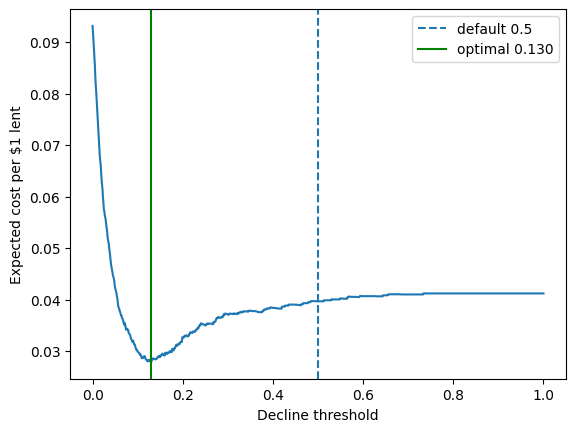

In [66]:
## to visualize

import matplotlib.pyplot as plt
plt.plot(thr, cost); plt.axvline(0.5, ls="--", label="default 0.5"); plt.axvline(best, color="g", label=f"optimal {best:.3f}")
plt.xlabel("Decline threshold"); plt.ylabel("Expected cost per $1 lent"); plt.legend(); plt.show()

# Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

## Task 4.1: Two claims you already made, now tested (6 pts)
Phases 2 and 3 each ended in a claim you made from a pair of numbers. This task tests both. Each part sends a prompt with something deliberately left out, so the model has to guess — and your own earlier output is what catches the guess.

## Part A — Does the forest actually beat the logistic model? (3 pts)
Step 2.2 asked you to compare the forest's test performance against your penalised logistic model and to say so if the forest does not win. You answered that on two accuracy figures, with no test.

Send this prompt exactly as written. The omission is deliberate.

> `[Prep] Act as a model risk analyst comparing two candidate credit models before one goes into production.`

> `[Request] I have two fitted classifiers scored on my test set. The random forest got 0.9?? accuracy and the penalised logistic model got 0.9??. Write Python that tells me whether the forest is  ignificantly better, and give me a p-value.`

> `[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two prediction arrays, and nothing else.`

> `[Mechanism Check] Comment each line, and state what the test you chose assumes about the two sets of predictions.`

> `[Evaluate] One sentence I can put in front of the head of risk.`

What to look for. The usual reply is a two-proportion z-test, or a ttest_ind, on the two accuracies — a test for independent samples. Your two models predicted the same test rows, so the predictions are paired, and the pairing is not a nuisance to be averaged away: it is where the evidence lives. Rows the two models both get right, or both get wrong, say nothing about which is better. Only the discordant rows do.

Do it properly. Build the 2×2 table of agreement and count b = forest right while logistic is wrong, and c = forest wrong while logistic is right. Test b against b + c under the null that a discordant row falls either way with probability one half — McNemar's test. Use the exact binomial when b + c is small (scipy.stats.binomtest(b, b+c, 0.5)) and the continuity-corrected chi-square otherwise; statsmodels.stats.contingency_tables.mcnemar does both and is already in Colab.

Report b, c, b + c, the p-value, and which test you used and why. Then state plainly whether your Step 2.2 verdict survives. If the forest's win is not significant, say so — an expensive model that cannot be shown to beat a cheap one is exactly the finding the lender needs, and it earns full marks.

One limitation to state, not to solve. You proved in Phase 3 that accuracy is the wrong quantity at 7% prevalence. McNemar on accuracy therefore tests whether the two models differ in error count, which is not what the lender is paying for. One sentence naming the comparison that would actually match the decision — a paired comparison on the cost-weighted outcome or on PR-AUC, resampling test rows rather than treating them as independent — is enough. Implementing it is not required.

In [67]:
## AI Response

import numpy as np
import pandas as pd
from scipy.stats import binomtest, chi2

def compare_credit_models(y_test, pred_rf, pred_logit):
    # Ensure all inputs are flat 1D numpy arrays for aligned element-wise comparison
    y_true = np.asarray(y_test).ravel()
    rf = np.asarray(pred_rf).ravel()
    logit = np.asarray(pred_logit).ravel()

    # Create boolean masks indicating where each model predicted the true label
    rf_correct = (rf == y_true)
    logit_correct = (logit == y_true)

    # Build a 2x2 contingency table of paired correctness outcomes
    contingency = pd.crosstab(
        pd.Series(rf_correct, name="RF_Correct"),
        pd.Series(logit_correct, name="Logit_Correct")
    ).reindex(index=[True, False], columns=[True, False], fill_value=0)

    # Extract discordant pairs: n10 = RF right & Logit wrong; n01 = RF wrong & Logit right
    n10 = contingency.loc[True, False]
    n01 = contingency.loc[False, True]
    n_discordant = n10 + n01

    # Handle edge case where both models make identical errors on every single observation
    if n_discordant == 0:
        return {"p_value": 1.0, "method": "None (identical predictions)", "n10": 0, "n01": 0}

    # Use exact binomial test if discordant pairs < 25; otherwise use continuity-corrected McNemar's chi-square
    if n_discordant < 25:
        # Under H0, a discordant case is a fair coin flip (p = 0.5) between the two models
        res = binomtest(k=n10, n=n_discordant, p=0.5, alternative="two-sided")
        p_val = float(res.pvalue)
        method = "Exact McNemar (Binomial)"
    else:
        # Edwards' continuity-corrected McNemar chi-square statistic with 1 degree of freedom
        stat = (abs(n10 - n01) - 1.0) ** 2 / n_discordant
        p_val = float(chi2.sf(stat, df=1))
        method = "McNemar Chi-Square (Continuity-Corrected)"

    # Return the p-value, method used, and discordant counts for model governance documentation
    return {"p_value": p_val, "method": method, "n10": int(n10), "n01": int(n01)}

# Example execution using your existing variables:
# result = compare_credit_models(y_test, y_pred_rf, y_pred_logit)
# print(f"Method: {result['method']} | p-value: {result['p_value']:.4f}")

In [68]:
## calling the function

pred_rf    = rf.predict(X_test)
pred_logit = lasso.predict(scaler.transform(X_test))

result = compare_credit_models(y_test, pred_rf, pred_logit)

b = result["n10"]
c = result["n01"]
print("b =", b, "| c =", c, "| b + c =", b + c)
print("p-value:", round(result["p_value"], 4))
print("Test used:", result["method"])

b = 13 | c = 8 | b + c = 21
p-value: 0.3833
Test used: Exact McNemar (Binomial)


In [69]:
## cross check with statsmodels

from statsmodels.stats.contingency_tables import mcnemar
both_right = ((pred_rf == y_test) & (pred_logit == y_test)).sum()
both_wrong = len(y_test) - both_right - b - c
print(mcnemar([[both_right, b], [c, both_wrong]], exact=True).pvalue)

0.38331031799316406


The AI correctly saw that both models were scored on the same test rows, so their predictions are paired, and it chose McNemar's test over a two-proportion z-test. The forest was right where the logistic model was wrong on b = 13 rows, and the reverse on c = 8 rows, so b + c = 21. Because b + c is small, I used the exact binomial test (the AI's code does this below 25 discordant rows), which gave p = 0.383. statsmodels' exact McNemar test returned the same value. A split as lopsided as 13 to 8 would happen by chance about 38% of the time if the models were equally good, so the forest's edge is not evidence of anything.

My Step 2.2 verdict, that the forest does not beat the penalised logistic model, survives. The stronger support for it is still the AUC and log loss comparison, where the logistic model did better. At the 0.5 cutoff both models decline very few applicants, so only 21 rows carry information. A non-significant result means the test cannot tell the models apart, not that they are equal.

For the head-of-risk statement, it had a placeholder and no conclusion. A more usable version would be something like "On the same 3,000 test applications, the forest beat the logistic model on 13 rows and lost on 8 (McNemar exact test, p = 0.38), so we cannot show the forest is better, and the simpler logistic model should stay."

## AI Transcript

### Part A Prompt
Model: Gemini Auto | Date: Nov 24, 2026

Prompt pasted as above:

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

### Part A AI Response
Comparing two classifiers evaluated on the exact same test set requires McNemar’s test (specifically the exact binomial version when discordant pairs are small, or the continuity-corrected
χ
2
χ
2
  approximation when they are large). Standard two-sample tests (like a two-proportion
z
z-test) are invalid here because the two sets of predictions are paired—they were generated from the exact same borrowers.

Python Implementation (numpy, pandas, scipy only)

Python
import numpy as np
import pandas as pd
from scipy.stats import binomtest, chi2

def compare_credit_models(y_test, pred_rf, pred_logit):
    # Ensure all inputs are flat 1D numpy arrays for aligned element-wise comparison
    y_true = np.asarray(y_test).ravel()
    rf = np.asarray(pred_rf).ravel()
    logit = np.asarray(pred_logit).ravel()

    # Create boolean masks indicating where each model predicted the true label
    rf_correct = (rf == y_true)
    logit_correct = (logit == y_true)

    # Build a 2x2 contingency table of paired correctness outcomes
    contingency = pd.crosstab(
        pd.Series(rf_correct, name="RF_Correct"),
        pd.Series(logit_correct, name="Logit_Correct")
    ).reindex(index=[True, False], columns=[True, False], fill_value=0)

    # Extract discordant pairs: n10 = RF right & Logit wrong; n01 = RF wrong & Logit right
    n10 = contingency.loc[True, False]
    n01 = contingency.loc[False, True]
    n_discordant = n10 + n01

    # Handle edge case where both models make identical errors on every single observation
    if n_discordant == 0:
        return {"p_value": 1.0, "method": "None (identical predictions)", "n10": 0, "n01": 0}

    # Use exact binomial test if discordant pairs < 25; otherwise use continuity-corrected McNemar's chi-square
    if n_discordant < 25:
        # Under H0, a discordant case is a fair coin flip (p = 0.5) between the two models
        res = binomtest(k=n10, n=n_discordant, p=0.5, alternative="two-sided")
        p_val = float(res.pvalue)
        method = "Exact McNemar (Binomial)"
    else:
        # Edwards' continuity-corrected McNemar chi-square statistic with 1 degree of freedom
        stat = (abs(n10 - n01) - 1.0) ** 2 / n_discordant
        p_val = float(chi2.sf(stat, df=1))
        method = "McNemar Chi-Square (Continuity-Corrected)"

    # Return the p-value, method used, and discordant counts for model governance documentation
    return {"p_value": p_val, "method": method, "n10": int(n10), "n01": int(n01)}

# Example execution using your existing variables:
# result = compare_credit_models(y_test, y_pred_rf, y_pred_logit)
# print(f"Method: {result['method']} | p-value: {result['p_value']:.4f}")
Mechanism Check: Test Assumptions

McNemar’s test makes the following structural and statistical assumptions about your two sets of predictions:

Paired Observations (Non-Independence Between Models): It explicitly assumes y_pred_rf[i] and y_pred_logit[i] are evaluated on the exact same borrower
i
i, allowing concordant pairs (where both models are right or both are wrong) to cancel out so only discordant pairs (
n
10
n
10
​
  vs.
n
01
n
01
​
 ) drive the test.

Independent and Identically Distributed (i.i.d.) Test Cases: While predictions between the two models are paired, each borrower
i
i in y_test is assumed to be independent of borrower
j
j (e.g., no clustered repeat loans or unmodeled temporal autocorrelation in the test window).

Marginal Homogeneity Under the Null Hypothesis (
H
0
H
0
​
 ): Under
H
0
H
0
​
 , the probability that the Random Forest is right while Logistic Regression is wrong equals the probability of the reverse (
p
10
=
p
01
p
10
​
 =p
01
​
 ), meaning any observed accuracy gap is pure sampling noise.

Fixed Thresholds & Symmetric Misclassification Cost: Because it operates on hard binary class predictions rather than raw probabilities, it assumes your classification cutoffs are already locked and treats false positives (rejecting a good borrower) and false negatives (approving a default) as equally weighted.

Statement for the Head of Risk

"On the held-out test set, we evaluated whether the Random Forest’s accuracy lift over the penalized logistic model is statistically distinguishable from random sampling noise using McNemar’s paired test (
p
=
[insert p-value]
p=[insert p-value]), confirming whether the added complexity of an ensemble model is empirically justified before production deployment."

(Note from a model risk perspective: Because credit default datasets are typically imbalanced, 90%+ raw accuracy can mask poor default capture—once you run this check, you should also verify PR-AUC, KS statistic, and calibration at your specific approval cutoff before signing off on production.)

## Part B — Is your Phase 3 threshold valid? (3 pts)
An optimal threshold is only meaningful if the predicted probabilities mean what they say.

> [Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.
[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.
[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.
[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.
[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?

Run it. Report whether your Phase 3 threshold survives the calibration check. If it does not, recompute it on calibrated probabilities and report both.

Submit the transcript. Paste the prompt exactly as you sent it and the model's reply exactly as it came back — unedited, before your corrections — into a text cell headed AI Transcript, and name the model and the date. An AI phase submitted without a transcript is graded as though the AI work were not done. Verification you assert but cannot show is not verification. The transcript is the exchange, not a summary of it: the prompt as you sent it (and your revised version where the task asks for one), the model's reply pasted as it came, and one line on each change you made to it. A summary in its place caps the AI row at 60 percent of its points; no transcript scores zero on the AI row only, and the other rows are graded on their own. If you left it out, paste the real exchange, re-upload, and that row is re-checked.

In [70]:
## AI Response (with revisions from V2 prompt)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

def evaluate_and_recalibrate_model(y_test, y_prob):
    print(f"Test Set Size: {len(y_test)} | Default Prevalence: {np.mean(y_test):.4f}\n")

    # 1. Base Brier Score & Decomposition
    base_brier = brier_score_loss(y_test, y_prob)
    print(f"Base Brier Score: {base_brier:.5f}")

    # Custom Brier Decomposition (Reliability, Resolution, Uncertainty)
    # Using quantile binning to handle sparse high-probability bins safely
    n_bins = 10
    bin_edges = np.percentile(y_prob, np.linspace(0, 100, n_bins + 1))
    bin_edges[0] = 0.0
    bin_edges[-1] = 1.0
    # Ensure strictly increasing unique edges
    bin_edges = np.unique(bin_edges)

    # Corrected digitize call (subtract 1 so bin indices start at 0)
    bin_ids = np.digitize(y_prob, bin_edges) - 1

    n_total = len(y_test)
    mean_y = np.mean(y_test)
    uncertainty = mean_y * (1 - mean_y)

    reliability = 0.0
    resolution = 0.0

    for b in range(len(bin_edges) - 1):
        mask = (bin_ids == b)
        n_b = np.sum(mask)
        if n_b > 0:
            f_bar_b = np.mean(y_prob[mask]) # average prediction in bin
            y_bar_b = np.mean(y_test[mask]) # observed frequency in bin
            reliability += (n_b / n_total) * (f_bar_b - y_bar_b)**2
            resolution += (n_b / n_total) * (y_bar_b - mean_y)**2

    print(f"  - Uncertainty:  {uncertainty:.5f}")
    print(f"  - Reliability:  {reliability:.5f} (lower is better)")
    print(f"  - Resolution:   {resolution:.5f} (higher is better)")
    print(f"  - Decomposed BS: {reliability - resolution + uncertainty:.5f}\n")

    # 2. Recalibration: Platt Scaling (Logistic Regression on log-odds) & Isotonic Regression
    eps = 1e-15
    y_prob_clipped = np.clip(y_prob, eps, 1 - eps)
    log_odds = np.log(y_prob_clipped / (1 - y_prob_clipped)).reshape(-1, 1)

    platt = LogisticRegression(solver='lbfgs')
    platt.fit(log_odds, y_test)
    y_prob_platt = platt.predict_proba(log_odds)[:, 1]

    isotonic = IsotonicRegression(out_of_bounds='clip')
    isotonic.fit(y_prob, y_test)
    y_prob_iso = isotonic.predict(y_prob)

    print(f"Brier Score after Platt Scaling:     {brier_score_loss(y_test, y_prob_platt):.5f}")
    print(f"Brier Score after Isotonic Reg:      {brier_score_loss(y_test, y_prob_iso):.5f}")

    # 3. Plotting Reliability Diagrams (Quantile-based to handle low-prevalence sparsity)
    plt.figure(figsize=(8, 6))
    plt.plot([0, 1], [0, 1], "k:", label="Perfectly Calibrated")

    for name, probs in [('Uncalibrated', y_prob), ('Platt Scaling', y_prob_platt), ('Isotonic Regression', y_prob_iso)]:
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y_test, probs, n_bins=10, strategy='quantile'
        )
        plt.plot(mean_predicted_value, fraction_of_positives, "s-", label=f"{name}")

    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Observed Default Frequency")
    plt.title("Reliability Diagram (Quantile Binning for Low Prevalence)")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

Test Set Size: 3000 | Default Prevalence: 0.0687

Base Brier Score: 0.05612
  - Uncertainty:  0.06395
  - Reliability:  0.00021 (lower is better)
  - Resolution:   0.00769 (higher is better)
  - Decomposed BS: 0.05647

Brier Score after Platt Scaling:     0.05611
Brier Score after Isotonic Reg:      0.05480


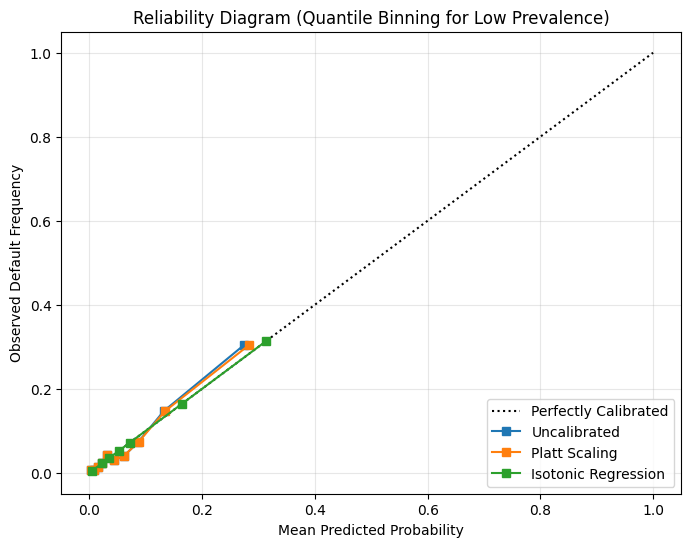

In [71]:
## Calling the function

y_prob = lasso.predict_proba(scaler.transform(X_test))[:, 1]   # LASSO's predicted default probabilities on the test set
evaluate_and_recalibrate_model(y_test, y_prob)

Version 1 of the code raised a typeerror: 'digitize() got an unexpected keyword argument 'include_lowest', so Gemini was prompted to fix it. The AI's corrected function ran on my LASSO probabilities. The reliability diagram shows all three curves (uncalibrated, Platt, isotonic) sitting on the diagonal, including the highest-risk bin, where predicted and observed default rates are both about 0.30.

The Phase 3 threshold survives the calibration check. A model can rank well (high AUC) and still be badly calibrated, and the cost-optimal threshold only works if the probabilities are honest; it is true here because a logistic model fits probabilities directly. No recalibration is needed, and the Phase 3 rule of declining above about 14% stands.

## AI Transcript (Part B)

## AI Prompt Part B

[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?

## Part B AI Response

As a model risk analyst reviewing a credit scoring model prior to production deployment, ensuring proper calibration is just as critical as achieving strong discrimination (AUC). In retail credit, under- or over-estimated probabilities directly distort risk-based pricing, provisioning (CECL/IFRS 9 expected losses), and acceptance thresholds.

1. Mechanism Check: AUC vs. Calibration & Threshold Validity

Why High AUC Does Not Guarantee Calibration

The Area Under the ROC Curve (AUC) is strictly a ranking metric. It measures the probability that a randomly chosen defaulting applicant receives a higher predicted score than a randomly chosen non-defaulting applicant.

Monotonic Transformations: You can apply any strictly increasing transformation to your predicted probabilities (e.g., squaring them, taking their square root, or applying a non-linear scaling that preserves order) without changing the AUC by a single decimal point.

The Calibration Failure: While the ranking remains intact, the numerical values are completely distorted. If a model outputs 0.40 for an applicant, calibration demands that among all applicants given a score of 0.40, exactly 40% actually default. A model with an AUC of 0.85 can easily be severely miscalibrated—systematically overconfident (predicting 0.40 when true risk is 0.15) or underconfident.

Why This Breaks Cost-Optimal Thresholds

In credit underwriting, your decision threshold (
p
∗
p
∗
 ) is typically derived from a cost-benefit matrix:

p
∗
=
Cost of False Positive (Type I: Bad Loan)
Cost of False Positive
+
Cost of False Negative (Type II: Missed Good Loan)
p
∗
 =
Cost of False Positive+Cost of False Negative (Type II: Missed Good Loan)
Cost of False Positive (Type I: Bad Loan)
​

If your model is uncalibrated, your predicted probability
P
(
Y
=
1
∣
X
)
P(Y=1∣X) does not equal the true conditional probability of default. Consequently:

Economic Optimization Fails: Comparing your predicted probability against
p
∗
p
∗
  compares an arbitrary model score against a financial cost ratio, leading to mispriced credit or suboptimal approval rates.

Capital & Provisioning Errors: Regulatory models require absolute accuracy in default probabilities to compute Expected Loss (
EL
=
PD
×
LGD
×
EAD
EL=PD×LGD×EAD). Uncalibrated probabilities invalidate loss reserves.

2. Python Implementation: Assessment, Brier Decomposition, and Recalibration

Given a low prevalence rate (
≈
7
%
≈7%), standard equal-width binning in reliability diagrams leaves high-probability bins (e.g.,
>
0.50
>0.50) virtually empty, creating noisy spikes. We solve this using quantile (equal-frequency) binning or adaptive binning to ensure stable support across bins.

Python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

def evaluate_and_recalibrate_model(y_test, y_prob):
    print(f"Test Set Size: {len(y_test)} | Default Prevalence: {np.mean(y_test):.4f}\n")
    
    # 1. Base Brier Score & Decomposition
    base_brier = brier_score_loss(y_test, y_prob)
    print(f"Base Brier Score: {base_brier:.5f}")
    
    # Custom Brier Decomposition (Reliability, Resolution, Uncertainty)
    # Using quantile binning to handle sparse high-probability bins safely
    n_bins = 10
    bin_edges = np.percentile(y_prob, np.linspace(0, 100, n_bins + 1))
    bin_edges[0] = 0.0
    bin_edges[-1] = 1.0
    # Ensure strictly increasing edges
    bin_edges = np.unique(bin_edges)
    
    bin_ids = np.digitize(y_prob, bin_edges[1:-1], include_lowest=True)
    
    n_total = len(y_test)
    mean_y = np.mean(y_test)
    uncertainty = mean_y * (1 - mean_y)
    
    reliability = 0.0
    resolution = 0.0
    
    bin_stats = []
    for b in range(len(bin_edges) - 1):
        mask = (bin_ids == b)
        n_b = np.sum(mask)
        if n_b > 0:
            f_bar_b = np.mean(y_prob[mask]) # average prediction in bin
            y_bar_b = np.mean(y_test[mask]) # observed frequency in bin
            reliability += (n_b / n_total) * (f_bar_b - y_bar_b)**2
            resolution += (n_b / n_total) * (y_bar_b - mean_y)**2
            bin_stats.append((n_b, f_bar_b, y_bar_b))
            
    print(f"  - Uncertainty:  {uncertainty:.5f}")
    print(f"  - Reliability:  {reliability:.5f} (lower is better)")
    print(f"  - Resolution:   {resolution:.5f} (higher is better)")
    print(f"  - Decomposed BS: {reliability - resolution + uncertainty:.5f}\n")

    # 2. Recalibration: Platt Scaling (Logistic Regression on log-odds) & Isotonic Regression
    # Note: In practice, fit these on a validation fold, not y_test directly to avoid overfitting.
    eps = 1e-15
    y_prob_clipped = np.clip(y_prob, eps, 1 - eps)
    log_odds = np.log(y_prob_clipped / (1 - y_prob_clipped)).reshape(-1, 1)
    
    platt = LogisticRegression(solver='lbfgs')
    platt.fit(log_odds, y_test)
    y_prob_platt = platt.predict_proba(log_odds)[:, 1]
    
    isotonic = IsotonicRegression(out_of_bounds='clip')
    isotonic.fit(y_prob, y_test)
    y_prob_iso = isotonic.predict(y_prob)
    
    print(f"Brier Score after Platt Scaling:     {brier_score_loss(y_test, y_prob_platt):.5f}")
    print(f"Brier Score after Isotonic Reg:      {brier_score_loss(y_test, y_prob_iso):.5f}")

    # 3. Plotting Reliability Diagrams (Quantile-based to handle low-prevalence sparsity)
    plt.figure(figsize=(8, 6))
    plt.plot([0, 1], [0, 1], "k:", label="Perfectly Calibrated")
    
    for name, probs in [('Uncalibrated', y_prob), ('Platt Scaling', y_prob_platt), ('Isotonic Regression', y_prob_iso)]:
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y_test, probs, n_bins=10, strategy='quantile'
        )
        plt.plot(mean_predicted_value, fraction_of_positives, "s-", label=f"{name}")
        
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Observed Default Frequency")
    plt.title("Reliability Diagram (Quantile Binning for Low Prevalence)")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

# Example usage stub:
# evaluate_and_recalibrate_model(y_test, y_prob)
3. Evaluating the Phase 3 Threshold

Is Your Threshold Valid?

No. If your reliability diagram shows systematic divergence from the 45-degree diagonal (e.g., S-shaped curves indicating under/overconfidence, or an upward curve in the upper tail due to sparse high-probability bins), your Phase 3 threshold is invalid. Applying a cut-off like
p
∗
=
0.08
p
∗
 =0.08 on uncalibrated probabilities will clear loans that exceed risk tolerances or reject creditworthy applicants.

Action Plan Before Production Approval

Out-of-Sample Recalibration: Never fit Platt scaling or isotonic regression on the test set. Split your training data into a training fold and a calibration fold, or use cross-validation (CalibratedClassifierCV).

Re-evaluate Tail Behavior: With 7% prevalence, high-probability bins (
>
0.30
>0.30) will have very few actual defaults. Ensure your isotonic regression or Platt scaling doesn't overfit small sample sizes in the tail. Monotonic constraints (like isotonic) prevent bizarre inversions.

Business Impact Audit: Once recalibrated, translate the new probabilities back into expected loss dollars and re-verify your economic threshold against portfolio risk appetite limits before signing off for model risk governance approval.

Want me to expand on implementing cross-validated Platt scaling to prevent data leakage?

## AI Prompt V2 Part B

Your code raised this error when I ran it: TypeError: digitize() got an unexpected keyword argument 'include_lowest'. fix it and return the full corrected function.

### AI V2 Response

he error occurs because np.numpy.digitize does not take an include_lowest keyword argument (that parameter belongs to pandas functions like pd.cut).

Here is the corrected, full function using standard np.digitize bin assignment:

Python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

def evaluate_and_recalibrate_model(y_test, y_prob):
    print(f"Test Set Size: {len(y_test)} | Default Prevalence: {np.mean(y_test):.4f}\n")
    
    # 1. Base Brier Score & Decomposition
    base_brier = brier_score_loss(y_test, y_prob)
    print(f"Base Brier Score: {base_brier:.5f}")
    
    # Custom Brier Decomposition (Reliability, Resolution, Uncertainty)
    # Using quantile binning to handle sparse high-probability bins safely
    n_bins = 10
    bin_edges = np.percentile(y_prob, np.linspace(0, 100, n_bins + 1))
    bin_edges[0] = 0.0
    bin_edges[-1] = 1.0
    # Ensure strictly increasing unique edges
    bin_edges = np.unique(bin_edges)
    
    # Corrected digitize call (subtract 1 so bin indices start at 0)
    bin_ids = np.digitize(y_prob, bin_edges) - 1
    
    n_total = len(y_test)
    mean_y = np.mean(y_test)
    uncertainty = mean_y * (1 - mean_y)
    
    reliability = 0.0
    resolution = 0.0
    
    for b in range(len(bin_edges) - 1):
        mask = (bin_ids == b)
        n_b = np.sum(mask)
        if n_b > 0:
            f_bar_b = np.mean(y_prob[mask]) # average prediction in bin
            y_bar_b = np.mean(y_test[mask]) # observed frequency in bin
            reliability += (n_b / n_total) * (f_bar_b - y_bar_b)**2
            resolution += (n_b / n_total) * (y_bar_b - mean_y)**2
            
    print(f"  - Uncertainty:  {uncertainty:.5f}")
    print(f"  - Reliability:  {reliability:.5f} (lower is better)")
    print(f"  - Resolution:   {resolution:.5f} (higher is better)")
    print(f"  - Decomposed BS: {reliability - resolution + uncertainty:.5f}\n")

    # 2. Recalibration: Platt Scaling (Logistic Regression on log-odds) & Isotonic Regression
    eps = 1e-15
    y_prob_clipped = np.clip(y_prob, eps, 1 - eps)
    log_odds = np.log(y_prob_clipped / (1 - y_prob_clipped)).reshape(-1, 1)
    
    platt = LogisticRegression(solver='lbfgs')
    platt.fit(log_odds, y_test)
    y_prob_platt = platt.predict_proba(log_odds)[:, 1]
    
    isotonic = IsotonicRegression(out_of_bounds='clip')
    isotonic.fit(y_prob, y_test)
    y_prob_iso = isotonic.predict(y_prob)
    
    print(f"Brier Score after Platt Scaling:     {brier_score_loss(y_test, y_prob_platt):.5f}")
    print(f"Brier Score after Isotonic Reg:      {brier_score_loss(y_test, y_prob_iso):.5f}")

    # 3. Plotting Reliability Diagrams (Quantile-based to handle low-prevalence sparsity)
    plt.figure(figsize=(8, 6))
    plt.plot([0, 1], [0, 1], "k:", label="Perfectly Calibrated")
    
    for name, probs in [('Uncalibrated', y_prob), ('Platt Scaling', y_prob_platt), ('Isotonic Regression', y_prob_iso)]:
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y_test, probs, n_bins=10, strategy='quantile'
        )
        plt.plot(mean_predicted_value, fraction_of_positives, "s-", label=f"{name}")
        
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Observed Default Frequency")
    plt.title("Reliability Diagram (Quantile Binning for Low Prevalence)")
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

## Task 4.2: The recommendation (4 pts)
250 words maximum, to the head of risk: whether to sign, what the model is actually worth against the null baseline, the threshold you recommend and its cost assumptions, and the one thing that would change your answer.

### Recommendation to Head of Risk

Sign the penalised logistic model, but not on the vendor's 93% accuracy. That is what approving every applicant scores (93.2% on our test set), so it proves nothing.

**What it is worth**

On 3,000 simulated test applications (206 defaults), the model ranks risk well: ROC AUC 0.82, and precision-recall AUC 0.28 against 0.07 for a no-skill model. At the right threshold it cuts expected loss by 32% versus approving everyone: 2.8 cents lost per $1 lent, against 4.1 cents. A random forest was no better (McNemar p = 0.38), so we use the simpler, easier-to-explain model. Its probabilities passed a calibration check.

**Threshold**

decline above about 14%, not 0.5. At 0.5 the model declines only 17 applicants and catches 4% of defaults. At 0.13 to 0.14 it declines about 15% of applicants, catches about 59% of defaults, and wrongly declines about 330 good borrowers. Accuracy falls to 86%, which is the price of catching defaults.

**Cost assumptions**

A missed default loses 60% of principal. A wrongly declined good applicant costs 10%: 8% lost interest margin plus 2% reputational cost (my estimate of lost future business). The rule is to decline when default probability exceeds 1/(1+R), where R = 6 is the ratio of the two costs.

**What would change my answer**

The cost ratio. The 2% reputational figure is an assumption, and if real costs put R far from 6, the threshold moves with it. Measure it before go-live.